# 04 · Customer, delivery, review & payment analysis
Questions: repeat purchasing · delivery performance · delivery ↔ review score · payment behaviour.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
BRL = mtick.FuncFormatter(lambda x, p: f"R${x/1e6:.1f}M" if abs(x) >= 1e6 else f"R${x/1e3:.0f}k")

In [2]:
f = pd.read_csv(olist.PROCESSED / "order_facts.csv.gz", parse_dates=olist.ORDER_DATE_COLS)
d = f[f.is_delivered].copy()
d["month"] = d.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
print(len(d), "delivered orders")

96470 delivered orders


## Chart 9 · Repeat customers (using `customer_unique_id`)

unique customers: 93,350 | repeat share: 3.00% | repeat customers' share of revenue: 5.5%
max orders by one customer: 15


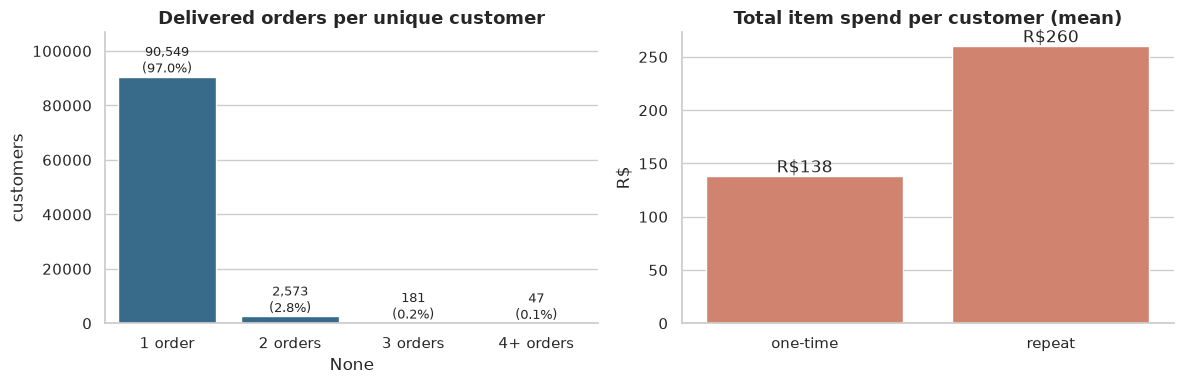

In [3]:
per = d.groupby("customer_unique_id").agg(n=("order_id","nunique"), spend=("item_revenue","sum"), first=("order_purchase_timestamp","min"))
dist = per.n.clip(upper=4).value_counts().sort_index()
dist.index = ["1 order","2 orders","3 orders","4+ orders"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=dist.index, y=dist.values, ax=axes[0], color="#2a6f97")
for i, v in enumerate(dist.values): axes[0].text(i, v, f"{v:,}\n({v/dist.sum():.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, dist.max()*1.18); axes[0].set_title("Delivered orders per unique customer"); axes[0].set_ylabel("customers")
rep = per.assign(rep=per.n > 1).groupby("rep").spend.agg(["count","mean","median"])
rep.index = ["one-time","repeat"]
sns.barplot(x=rep.index, y=rep["mean"], ax=axes[1], color="#e07a5f")
for i, v in enumerate(rep["mean"]): axes[1].text(i, v, f"R${v:.0f}", ha="center", va="bottom")
axes[1].set_title("Total item spend per customer (mean)"); axes[1].set_ylabel("R$"); axes[1].set_xlabel("")
plt.tight_layout(); olist.save_fig(fig, "09_repeat_customers.png")
share = (per.n > 1).mean(); rep_rev = per[per.n>1].spend.sum()/per.spend.sum()
print(f"unique customers: {len(per):,} | repeat share: {share:.2%} | repeat customers' share of revenue: {rep_rev:.1%}")
print(f"max orders by one customer: {per.n.max()}")

**Interpretation.** Only **~3%** of customers ever buy twice — this is a *one-and-done* marketplace (a known feature of this dataset). Repeat customers spend about twice as much in total and are ~6% of revenue. **Limitation:** customers are tracked only over ~2 years and only by `customer_unique_id`; later cohorts have had less time to return (right-censoring, see SQL q20), so the true repeat rate for old cohorts could be somewhat higher than for new ones.

In [4]:
# Cohort view: % repeat by first-purchase quarter (the later cohorts are right-censored)
per["cohort"] = per["first"].dt.to_period("Q")
co = per[(per["first"] >= "2017-01-01") & (per["first"] < "2018-07-01")].groupby("cohort").agg(customers=("n","size"), pct_repeat=("n", lambda s: 100*(s>1).mean()))
co.round(2)

,customers,pct_repeat
cohort,,
2017Q1,4848,4.93
2017Q2,8743,5.09
2017Q3,11813,4.62
2017Q4,16725,3.12
2018Q1,19904,3.04
2018Q2,18963,1.62


## Chart 10 · Delivery performance

median actual 10.2d | mean 12.6d | p95 29d | median estimate 23d
overall late rate 8.11% | worst months:
month
2018-03-01   21.40
2018-02-01   16.00
2017-11-01   14.30
2018-08-01   10.40


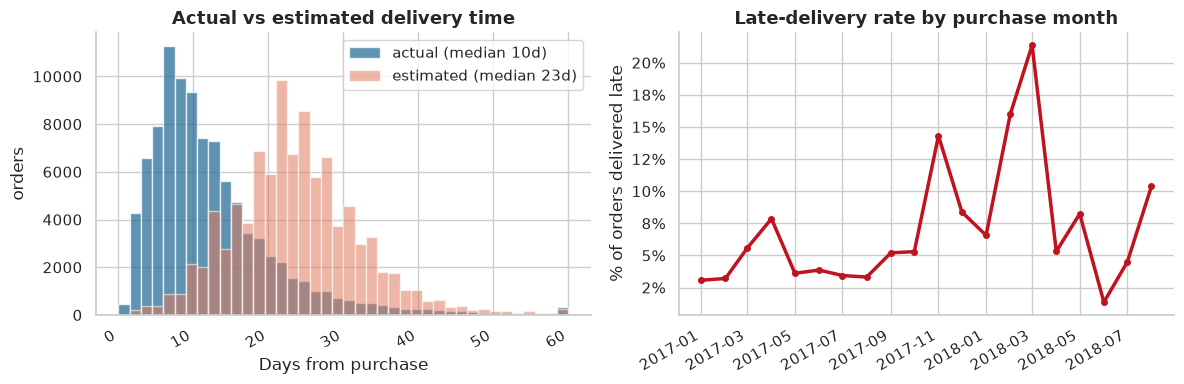

In [5]:
dd = d.dropna(subset=["delivery_days"])
est = (dd.order_estimated_delivery_date - dd.order_purchase_timestamp).dt.total_seconds()/86400
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(0, 61, 1.5)
axes[0].hist(dd.delivery_days.clip(upper=60), bins=bins, alpha=.75, color="#2a6f97", label=f"actual (median {dd.delivery_days.median():.0f}d)")
axes[0].hist(est.clip(upper=60), bins=bins, alpha=.55, color="#e07a5f", label=f"estimated (median {est.median():.0f}d)")
axes[0].legend(); axes[0].set_xlabel("Days from purchase"); axes[0].set_ylabel("orders"); axes[0].set_title("Actual vs estimated delivery time")
mm = dd[(dd.order_purchase_timestamp>=olist.TREND_START)&(dd.order_purchase_timestamp<olist.TREND_END)].groupby("month").agg(late=("is_late","mean"), days=("delivery_days","mean"))
axes[1].plot(mm.index, mm.late*100, color="#c1121f", lw=2.5, marker="o", ms=4)
axes[1].set_ylabel("% of orders delivered late"); axes[1].set_title("Late-delivery rate by purchase month")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); fig.autofmt_xdate()
plt.tight_layout(); olist.save_fig(fig, "10_delivery_performance.png")
print(f"median actual {dd.delivery_days.median():.1f}d | mean {dd.delivery_days.mean():.1f}d | p95 {dd.delivery_days.quantile(.95):.0f}d | median estimate {est.median():.0f}d")
print(f"overall late rate {dd.is_late.mean():.2%} | worst months:"); print((mm.late*100).round(1).sort_values(ascending=False).head(4).to_string())

**Interpretation.** Olist's delivery *estimates are conservative* (median ≈ 23 days promised vs ≈ 10 delivered), so only ~8% of orders arrive late overall. But lateness is **not uniform**: Nov 2017 (Black Friday), Feb–Mar 2018 spike to 14–21% late. Those are demand-surge / logistics-capacity failures, and exactly where review damage concentrates (next chart).

## Chart 11 · Delivery delay vs review score

                     n  mean
bucket                      
7+ days\nearly   70929  4.32
0-7 days\nearly  17234  4.20
0-3 days\nlate    2636  3.77
3-7 days\nlate    1773  2.32
7+ days\nlate     3252  1.73

late orders = 8.0% of reviewed orders but 33.8% of all 1-2 star reviews


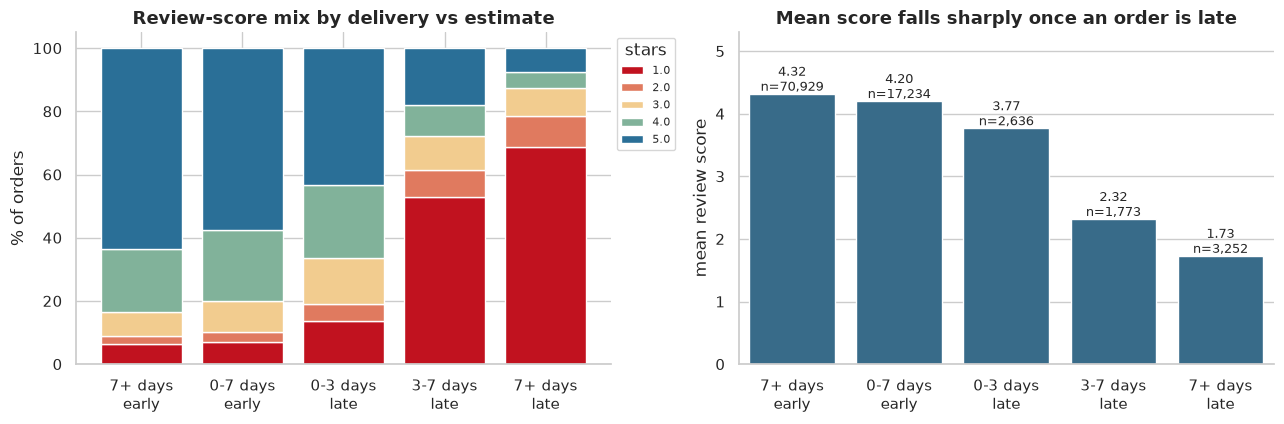

In [6]:
rv = d.dropna(subset=["review_score","days_vs_estimate"]).copy()
bins = [-np.inf, -7, 0, 3, 7, np.inf]; labels = ["7+ days\nearly","0-7 days\nearly","0-3 days\nlate","3-7 days\nlate","7+ days\nlate"]
rv["bucket"] = pd.cut(rv.days_vs_estimate, bins=bins, labels=labels, right=True)
agg = rv.groupby("bucket").agg(n=("review_score","size"), mean=("review_score","mean"))
dist = pd.crosstab(rv.bucket, rv.review_score, normalize="index")*100
pal = ["#c1121f","#e07a5f","#f2cc8f","#81b29a","#2a6f97"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
dist.plot(kind="bar", stacked=True, ax=axes[0], color=pal, width=.8, legend=False)
axes[0].set_ylabel("% of orders"); axes[0].set_xlabel(""); axes[0].set_title("Review-score mix by delivery vs estimate"); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="stars", bbox_to_anchor=(1.0, 1), loc="upper left", fontsize=8)
sns.barplot(x=agg.index, y=agg["mean"], ax=axes[1], color="#2a6f97")
for i, (v, n) in enumerate(zip(agg["mean"], agg["n"])): axes[1].text(i, v+.05, f"{v:.2f}\nn={n:,}", ha="center", fontsize=9)
axes[1].set_ylim(0, 5.3); axes[1].set_ylabel("mean review score"); axes[1].set_xlabel(""); axes[1].set_title("Mean score falls sharply once an order is late")
plt.tight_layout(); olist.save_fig(fig, "11_delay_vs_review.png")
print(agg.round(3).to_string())
late = rv[rv.is_late==1]; ont = rv[rv.is_late==0]
print(f"\nlate orders = {len(late)/len(rv):.1%} of reviewed orders but {(late.review_score<=2).sum()/(rv.review_score<=2).sum():.1%} of all 1-2 star reviews")

**Interpretation.** Being **on time or early barely matters** (4.3 vs 4.2 stars), but once an order is late the score drops off a cliff: 3–7 days late ≈ 2.3 stars and 7+ days late ≈ 1.7 stars. Late orders are a small slice of volume but a **disproportionately large share of all 1–2★ reviews**. Formal tests are in notebook 05. *Caveat:* this is observational — late orders may differ in other ways (distance, category, seller).

## Chart 12 · Payment behaviour

              count   mean  median
payment_type                      
credit_card   76795 163.30  106.90
boleto        19784 145.00   93.90
voucher        5775  65.70   39.30
debit_card     1529 142.60   89.30

credit-card payments in >1 instalment: 66.9% | mean instalments 3.51


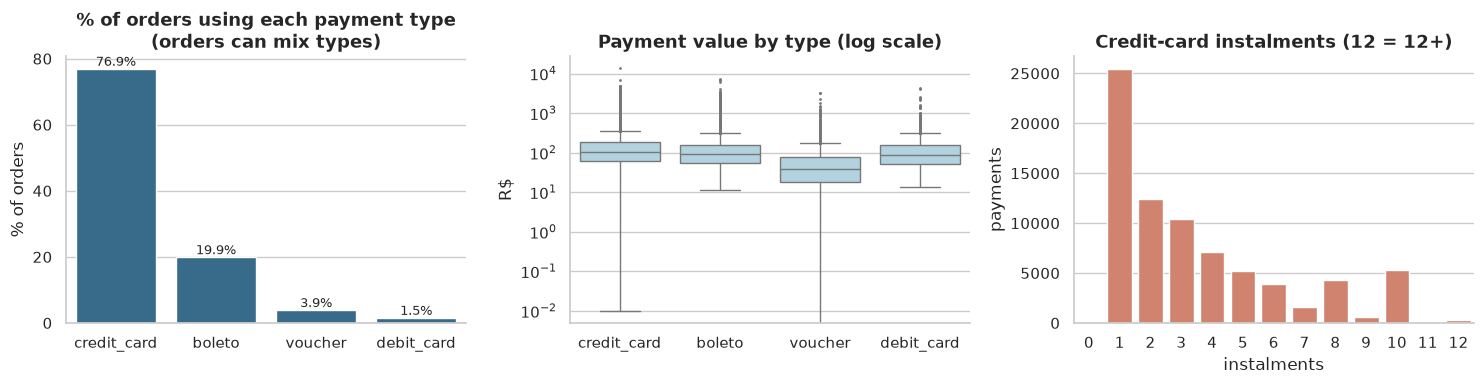

In [7]:
pay = olist.load_raw(["payments"])["payments"]
pay = pay[pay.payment_type != "not_defined"]
share = pay.groupby("payment_type").order_id.nunique().sort_values(ascending=False)
share_pct = 100*share/f.order_id.nunique()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(x=share_pct.index, y=share_pct.values, ax=axes[0], color="#2a6f97"); axes[0].set_title("% of orders using each payment type\n(orders can mix types)"); axes[0].set_ylabel("% of orders"); axes[0].set_xlabel("")
for i, v in enumerate(share_pct.values): axes[0].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
order = share.index
sns.boxplot(data=pay, x="payment_type", y="payment_value", order=order, ax=axes[1], color="#a9d6e5", fliersize=1)
axes[1].set_yscale("log"); axes[1].set_title("Payment value by type (log scale)"); axes[1].set_xlabel(""); axes[1].set_ylabel("R$")
cc = pay[pay.payment_type=="credit_card"].payment_installments.clip(upper=12).value_counts().sort_index()
sns.barplot(x=cc.index, y=cc.values, ax=axes[2], color="#e07a5f"); axes[2].set_title("Credit-card instalments (12 = 12+)"); axes[2].set_xlabel("instalments"); axes[2].set_ylabel("payments")
plt.tight_layout(); olist.save_fig(fig, "12_payments.png")
print(pay.groupby("payment_type").payment_value.agg(["count","mean","median"]).loc[order].round(1).to_string())
cc_all = pay[pay.payment_type=="credit_card"]
print(f"\ncredit-card payments in >1 instalment: {(cc_all.payment_installments>1).mean():.1%} | mean instalments {cc_all.payment_installments.mean():.2f}")

**Interpretation.** Credit card dominates (~77% of orders), boleto (bank slip) is ~20%. Voucher payments are small (median ≈ R$40) and often *partial* (an order mixes voucher + card). About two-thirds of card payments are split into instalments — installment affordability is a core part of purchasing in this market.

## Extra · Freight burden by category

overall freight share of GMV: 14.3%


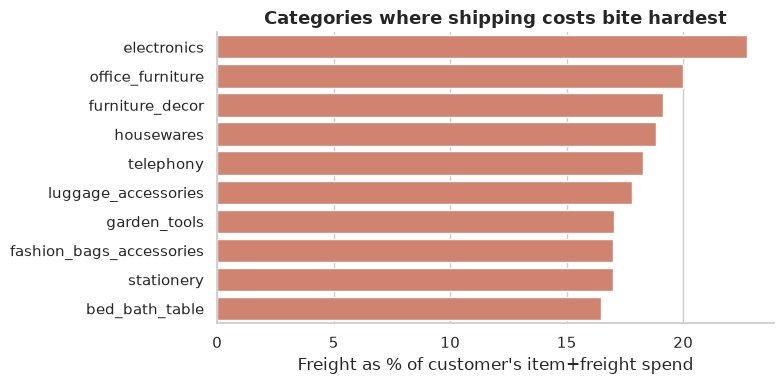

In [8]:
cat = olist.category_table(olist.load_raw(["products","translation"]))[["product_id","category"]]
it = olist.load_raw(["items"])["items"].merge(d[["order_id"]], on="order_id").merge(cat, on="product_id", how="left")
fr = it.groupby("category").agg(items=("price","size"), price=("price","sum"), freight=("freight_value","sum"))
fr = fr[fr["items"]>=500]; fr["freight_pct"] = 100*fr.freight/(fr.price+fr.freight)
top = fr.sort_values("freight_pct", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=top.freight_pct, y=top.index, ax=ax, color="#e07a5f"); ax.set_xlabel("Freight as % of customer's item+freight spend"); ax.set_ylabel("")
ax.set_title("Categories where shipping costs bite hardest")
plt.tight_layout(); olist.save_fig(fig, "13_freight_burden.png")
print(f"overall freight share of GMV: {100*it.freight_value.sum()/(it.price.sum()+it.freight_value.sum()):.1f}%")

**Interpretation.** Bulky/low-price goods (electronics, furniture, housewares) pay ~19–23% of their spend as freight vs ~14% overall. Freight is a plausible conversion barrier for these categories — worth testing free-shipping thresholds.